# Interpretabilitas Model

Tahap ini menggunakan model dan hasil prediksi dari notebook 03 untuk melihat kontribusi indikator teknikal. Gain Importance, Permutation Importance, dan SHAP dihitung untuk setiap saham, lalu hasilnya dibandingkan.

## Persiapan

Library, jumlah pengacakan fitur, dan pengaturan grafik disiapkan sebelum perhitungan. Nama fitur pada tabel dan grafik dirapikan melalui display_names.

In [1]:
# import library
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.inspection import permutation_importance

import sys
# biar file .py di folder utama bisa di-import dari folder notebooks
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline_utils import show_table

from notebook_config import (
    blue,
    configure_notebook,
    feature_columns as features,
    orange,
    quarter_codes,
    random_seed,
    target,
    tickers,
)


In [2]:
# mengatur folder dan pengaturan perhitungan serta grafik
root_dir, output_dir = configure_notebook()
processed_dir = root_dir / "data" / "processed"
output_dir = output_dir / "research"
output_dir.mkdir(parents=True, exist_ok=True)

model_dir = output_dir / "xgb_models"

green = "#70AD47"

# menentukan jumlah pengacakan untuk setiap fitur
permutation_repeats = 10

# membatasi grafik sampai 200 titik per fitur
plot_sample_size = 200

# memilih enam fitur dengan rata-rata nilai absolut SHAP tertinggi
plot_feature_count = 6

# folder gambar yang dipakai pada dokumen
figure_dir = output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

# merapikan nama fitur pada grafik dan tabel
display_names = {
    "ATR14": "ATR 14",
    "BB_Lower": "Bollinger Lower",
    "BB_Upper": "Bollinger Upper",
    "EMA10": "EMA 10",
    "Mean Rank": "Mean Rank",
    "Mean_Gain": "Mean Gain",
    "Mean_Permutation": "Mean RMSE Change",
    "Mean_SHAP": "Mean Absolute SHAP Value",
    "RSI14": "RSI 14",
    "Rank Gain": "Gain Rank",
    "Rank Permutation": "Permutation Rank",
    "Rank SHAP": "SHAP Rank",
    "SMA10": "SMA 10",
    "SMA20": "SMA 20",
    "Signal": "MACD Signal",
    "Stochastic_%K": "Stochastic %K",
    "Indikator Teknikal": "Technical Indicator"
}


## Load Prediksi dan Model

Prediksi dibaca dari predictions_2025.parquet, lalu model dimuat sesuai saham dan kuartalnya. Kelengkapan sebelas saham dan empat kuartal diperiksa sebelum menghitung kepentingan fitur.

In [3]:
# membaca prediksi 2025 dari notebook 03 dan mengecek lengkap 11 saham x 4 kuartal
predictions = pd.read_parquet(processed_dir / "predictions_2025.parquet")
predictions["snapshot_date"] = pd.to_datetime(predictions["snapshot_date"])

if set(predictions["Kode Saham"].unique()) != set(tickers):
    raise ValueError("Prediksi belum sesuai 11 saham. Jalankan Notebook 03 dahulu.")
# mengecek prediksi tiap saham pada keempat kuartal
if predictions.groupby(["Kode Saham", "quarter"]).size().shape[0] != len(tickers) * len(quarter_codes):
    raise ValueError('Prediksi belum lengkap untuk 44 pasangan saham-quarter')


In [4]:
# membaca model sesuai saham dan kuartalnya
models = {}
for ticker in tickers:
    for quarter, quarter_code in quarter_codes.items():
        model = xgb.XGBRegressor()
        model.load_model(model_dir / f"xgb_{ticker}_{quarter_code}.json")
        models[(ticker, quarter)] = model

assert len(models) == len(tickers) * len(quarter_codes)

show_table(pd.DataFrame({"Keterangan": ['Quarterly Model', 'Test Observations'], "Nilai": [len(models), len(predictions)]}), display_names=display_names)


,Keterangan,Nilai
0,Quarterly Model,44
1,Test Observations,"2,585"


## Gain Importance

Total gain setiap fitur diambil dari model dan dibagi dengan jumlah total gain pada model tersebut. Hasilnya dirata-ratakan antar kuartal untuk setiap saham, lalu dirata-ratakan pada sebelas saham.

In [5]:
# Gain Importance: seberapa besar fitur bantu menurunkan error waktu dipakai buat membelah pohon
# dihitung dari model langsung, tidak pakai data test
gain_by_ticker = {}
for ticker in tickers:
    quarterly_gain = []
    for quarter in quarter_codes:
        # mengambil total_gain setiap fitur dari model
        scores = models[(ticker, quarter)].get_booster().get_score(importance_type="total_gain")
        values = np.array([scores.get(feature, 0.0) for feature in features], dtype=float)
        # membagi nilai setiap fitur dengan total gain model agar skalanya sama
        if values.sum() > 0:
            values = values / values.sum()
        quarterly_gain.append(values)
    # menghitung rata-rata empat model kuartalan untuk saham ini
    gain_by_ticker[ticker] = np.mean(quarterly_gain, axis=0)

gain_importance = pd.DataFrame(gain_by_ticker, index=features)
# memberi bobot yang sama pada setiap saham dalam rata-rata gabungan
gain_importance["Mean_Gain"] = gain_importance.mean(axis=1)
gain_importance = gain_importance.sort_values("Mean_Gain", ascending=False)
gain_importance.to_parquet(output_dir / "gain_importance_normalized.parquet")
show_table(gain_importance, display_names=display_names)


,BBCA,BBNI,BBRI,BBTN,BDMN,BJBR,BMRI,BNGA,BNLI,BTPS,PNBN,Mean Gain
RSI 14,0.162951,0.12712,0.0515852,0.0514304,0.034182,0.0379771,0.827676,0,0.436894,0.00819551,0.159715,0.172521
ATR 14,0.110417,0.164851,0.0251374,0.353252,0.127321,0.167772,0.0176483,0,0.119965,0.557603,0.0875272,0.157409
EMA 10,0.100212,0.0271622,0.0108902,0.00561068,0.216587,0.579635,0,0,0.0132274,0.00562121,0.0761926,0.0941034
MACD,0.104655,0.0331556,0.219655,0.0126665,0.207528,0.0433423,0.115173,0,0.0818442,0.101061,0.113287,0.0938516
SMA 20,0.084295,0.0522904,0.247225,0.318913,0.0496825,0.0218054,0,0,0.000494521,0.146096,0.0503489,0.0882864
Stochastic %K,0.102549,0.0241763,0.264067,0.0766082,0.0569291,0.0188779,0.0336294,0,0.214405,0.00732338,0.122838,0.0837639
Bollinger Lower,0.0637015,0.269789,0.0139048,0.00562163,0.0370575,0.0706529,0.00587268,0,0.0836748,0,0.118786,0.0608237
Bollinger Upper,0.0857282,0.00635275,0.0814576,0.0666032,0.164777,0.0164823,0,0,0.00377005,0.121706,0.0718086,0.0562442
SMA 10,0.0997935,0.197665,0.0835097,0.0475128,0.0718482,0,0,0,0,0.0012287,0.067794,0.0517592
MACD Signal,0.0856976,0.0974392,0.00256739,0.0617814,0.0340883,0.0434557,0,0,0.0457251,0.051165,0.131703,0.0503293


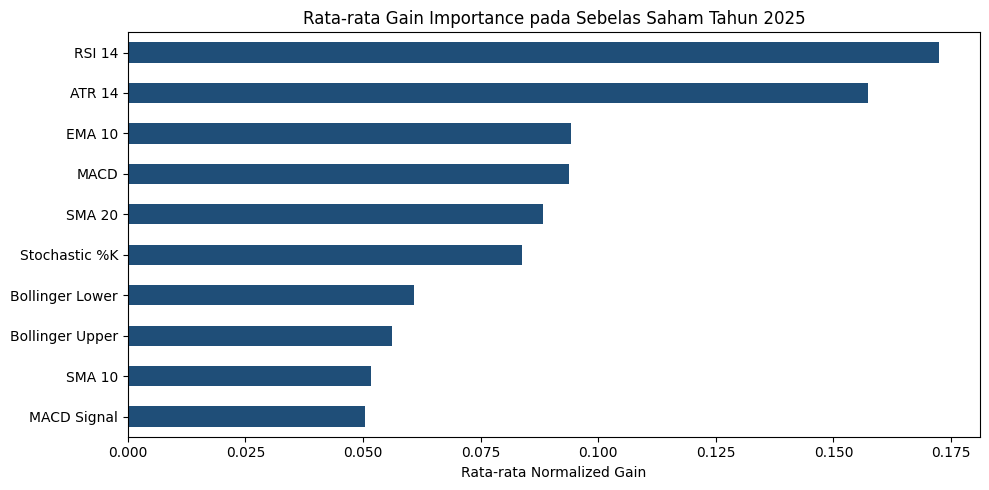

In [6]:
# menampilkan rata-rata gain dari fitur dengan nilai terendah ke tertinggi
fig, axis = plt.subplots(figsize=(10, 5))
gain_importance["Mean_Gain"].sort_values().rename(index=display_names).plot.barh(ax=axis, color=blue)
axis.set_title('Rata-rata Gain Importance pada Sebelas Saham Tahun 2025')
axis.set_xlabel('Rata-rata Normalized Gain')
fig.tight_layout()
fig.savefig(figure_dir / "gambar_gain_importance.png", dpi=200, bbox_inches="tight")
plt.show()


## Permutation Importance

Nilai setiap fitur diacak sepuluh kali pada test set saham dan kuartal yang sama. Kenaikan RMSE setelah pengacakan dirata-ratakan antar kuartal dengan jumlah observasi sebagai bobot, lalu dirata-ratakan antar saham.

In [7]:
# Permutation Importance: mengacak nilai satu fitur di data test lalu melihat RMSE naik berapa
# makin naik RMSE-nya, makin penting fiturnya
permutation_by_ticker = {}
for ticker in tickers:
    weighted_values = np.zeros(len(features))
    total_rows = 0
    for quarter in quarter_codes:
        quarter_rows = predictions[(predictions["Kode Saham"] == ticker) & (predictions["quarter"] == quarter)]
        # mengacak satu fitur pada test set saham dan kuartal yang sama
        result = permutation_importance(
            models[(ticker, quarter)],
            quarter_rows[features],
            quarter_rows[target],
            scoring="neg_root_mean_squared_error",
            n_repeats=permutation_repeats,
            random_state=random_seed,
        )
        # memakai jumlah observasi sebagai bobot rata-rata antar kuartal
        weighted_values += result.importances_mean * len(quarter_rows)
        total_rows += len(quarter_rows)
    permutation_by_ticker[ticker] = weighted_values / total_rows

permutation_importance_df = pd.DataFrame(permutation_by_ticker, index=features)
# menghitung rata-rata hasil pengacakan dari sebelas saham
permutation_importance_df["Mean_Permutation"] = permutation_importance_df.mean(axis=1)
permutation_importance_df = permutation_importance_df.sort_values("Mean_Permutation", ascending=False)
permutation_importance_df.to_parquet(output_dir / "permutation_importance.parquet")
show_table(permutation_importance_df, display_names=display_names)


,BBCA,BBNI,BBRI,BBTN,BDMN,BJBR,BMRI,BNGA,BNLI,BTPS,PNBN,Mean RMSE Change
Stochastic %K,0.000197982,-1.30925e-06,-2.81323e-05,-1.72764e-07,-2.32613e-05,5.59531e-07,1.35195e-06,0,0.00206303,6.64063e-06,0.000252243,0.000224449
RSI 14,0.000396644,-2.08631e-06,1.59882e-05,-3.07362e-07,-9.34943e-06,-1.30199e-05,1.58947e-06,0,0.00110269,-1.30927e-06,0.00017512,0.000151451
MACD Signal,3.1294e-05,0,0,0,-1.48828e-06,0,0,0,0.000451455,0,0.000804764,0.000116911
MACD,-0.000322626,-8.35509e-06,8.9052e-07,-6.4595e-06,-1.35154e-06,1.90612e-06,0,0,4.72731e-05,-4.43838e-06,0.00109657,7.30373e-05
EMA 10,8.70398e-06,5.45257e-07,0,1.26933e-07,2.2493e-05,0.00012423,0,0,-4.81202e-05,5.56221e-07,0.000545524,5.946e-05
SMA 10,0.000107504,0,0,7.08011e-07,1.20393e-06,0,0,0,0,0,0.000169634,2.53682e-05
SMA 20,8.50475e-05,0,5.12129e-05,0,0,3.80932e-06,0,0,-1.1363e-05,0,3.63894e-06,1.20314e-05
Bollinger Lower,-8.48296e-05,0,-3.4572e-07,0,0,0,0,0,0,0,0.000190942,9.61517e-06
ATR 14,-8.4557e-05,-5.10937e-05,-5.41222e-06,-5.8738e-05,0,0,7.75459e-06,0,9.14848e-05,-1.08926e-06,0.000191496,8.16774e-06
Bollinger Upper,-0.000122086,0,0,0,3.91398e-05,4.84591e-05,0,0,0,0,2.69633e-05,-6.83987e-07


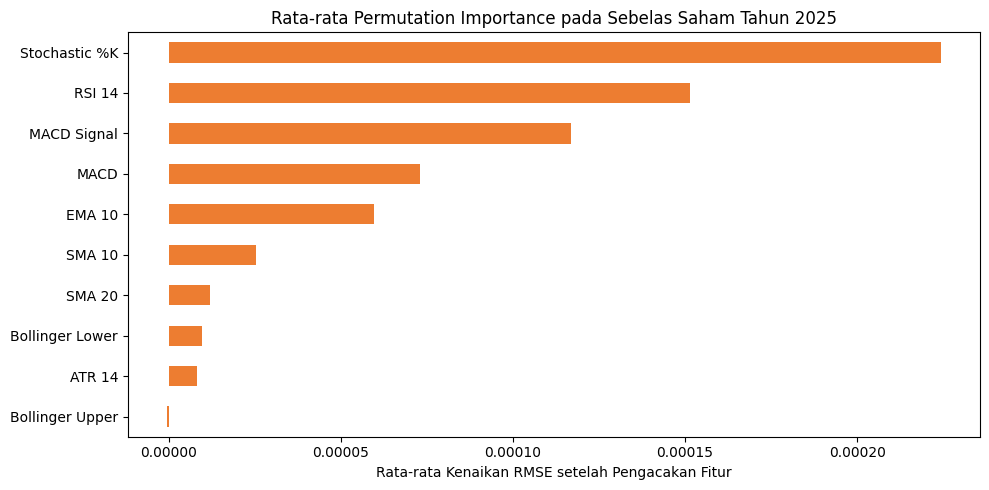

In [8]:
# menampilkan kenaikan RMSE setelah nilai fitur diacak
fig, axis = plt.subplots(figsize=(10, 5))
permutation_importance_df["Mean_Permutation"].sort_values().rename(index=display_names).plot.barh(ax=axis, color=orange)
axis.set_title("Rata-rata Permutation Importance pada Sebelas Saham Tahun 2025")
axis.set_xlabel('Rata-rata Kenaikan RMSE setelah Pengacakan Fitur')
fig.tight_layout()
fig.savefig(figure_dir / "gambar_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()


## SHAP

Kontribusi fitur dihitung untuk setiap prediksi menggunakan model saham dan kuartal yang sesuai. Nilai absolut SHAP dirata-ratakan pada seluruh observasi setiap saham, lalu dirata-ratakan pada sebelas saham dengan bobot yang sama.

In [9]:
# SHAP: kontribusi tiap fitur di setiap prediksi
# positif membuat prediksi naik, negatif membuat turun
# nilainya dihitung langsung sama XGBoost (pred_contribs=True)
shap_by_ticker = {}
shap_rows = {}
feature_rows = {}

for ticker in tickers:
    ticker_shap_parts = []
    ticker_feature_parts = []
    for quarter in quarter_codes:
        quarter_rows = predictions[(predictions["Kode Saham"] == ticker) & (predictions["quarter"] == quarter)]
        matrix = xgb.DMatrix(quarter_rows[features], feature_names=features)
        # mengambil kontribusi fitur dengan melewati kolom terakhir yang berisi base value
        contributions = models[(ticker, quarter)].get_booster().predict(matrix, pred_contribs=True)[:, :-1]
        ticker_shap_parts.append(contributions)
        ticker_feature_parts.append(quarter_rows[features].to_numpy())
    # menggabungkan kontribusi dari seluruh observasi pada empat kuartal
    combined_shap = np.vstack(ticker_shap_parts)
    combined_features = np.vstack(ticker_feature_parts)
    # menghitung rata-rata nilai absolut SHAP untuk saham ini
    shap_by_ticker[ticker] = np.abs(combined_shap).mean(axis=0)
    shap_rows[ticker] = combined_shap
    feature_rows[ticker] = combined_features

shap_importance = pd.DataFrame(shap_by_ticker, index=features)
# menghitung rata-rata SHAP dari sebelas saham dengan bobot yang sama
shap_importance["Mean_SHAP"] = shap_importance.mean(axis=1)
shap_importance = shap_importance.sort_values("Mean_SHAP", ascending=False)
shap_importance.to_parquet(output_dir / "shap_importance.parquet")
show_table(shap_importance, display_names=display_names)


,BBCA,BBNI,BBRI,BBTN,BDMN,BJBR,BMRI,BNGA,BNLI,BTPS,PNBN,Mean Absolute SHAP Value
RSI 14,0.0023487,4.23613e-05,7.03395e-05,3.89431e-05,5.71074e-05,7.76611e-05,2.44948e-05,0,0.00609794,9.61779e-06,0.00142091,0.000926188
ATR 14,0.00262812,0.000575245,5.57087e-05,0.000383781,0.000102046,3.88849e-05,0.000142137,0,0.00439325,0.0006115,0.000895469,0.000893285
Stochastic %K,0.0019488,1.29769e-05,0.000281796,7.38354e-05,6.85123e-05,1.03666e-05,8.66345e-06,0,0.00281299,2.24526e-05,0.00161143,0.000622894
MACD Signal,0.00177872,3.2954e-05,2.4632e-06,1.2192e-05,0.000149913,2.22217e-05,0,0,0.000703809,7.79575e-05,0.00388299,0.000605747
EMA 10,0.000538229,4.39186e-05,1.07817e-06,4.3631e-05,0.000498565,0.00082227,0,0,0.001456,4.8485e-06,0.00211198,0.000501865
MACD,0.00225556,3.31441e-05,0.000123597,3.69752e-05,0.000309984,2.69051e-05,7.23298e-08,0,0.000366099,7.52673e-05,0.00195913,0.000471522
Bollinger Upper,0.00114789,1.27635e-06,4.68278e-05,0.000185918,0.000203785,2.94812e-05,0,0,0.000495679,5.73378e-05,0.00175291,0.000356464
Bollinger Lower,0.000956026,0.000109955,1.2821e-05,2.52415e-05,0.000246082,3.8013e-05,1.77205e-07,0,0.000310952,0,0.00174585,0.000313193
SMA 20,0.000574556,7.51392e-06,0.000193796,0.00081149,0.000223177,0.000243064,0,0,2.68819e-05,0.000418905,0.000327422,0.000256982
SMA 10,0.000473285,1.3085e-05,1.04202e-05,5.26198e-05,7.55259e-05,0,0,0,0,0.000146427,0.0010106,0.000161997


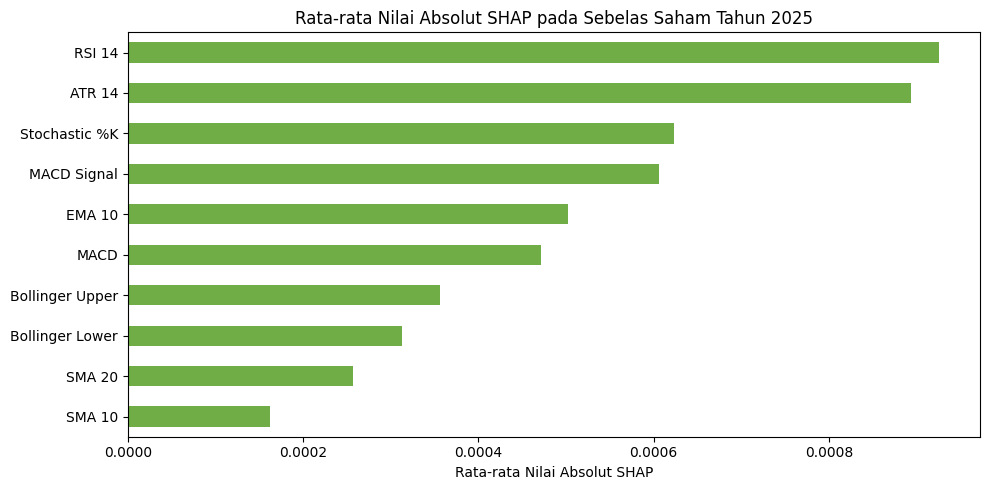

In [10]:
fig, axis = plt.subplots(figsize=(10, 5))
# menampilkan rata-rata nilai absolut SHAP yang sudah dihitung
shap_importance["Mean_SHAP"].sort_values().rename(index=display_names).plot.barh(ax=axis, color=green)
axis.set_title("Rata-rata Nilai Absolut SHAP pada Sebelas Saham Tahun 2025")
axis.set_xlabel("Rata-rata Nilai Absolut SHAP")
fig.tight_layout()
fig.savefig(figure_dir / "gambar_shap_importance.png", dpi=200, bbox_inches="tight")
plt.show()


## Grafik SHAP per Saham

Sebaran kontribusi fitur ditampilkan untuk sebelas saham yang dibagi ke dalam dua gambar. Setiap grafik memuat enam fitur dengan rata-rata nilai absolut SHAP tertinggi pada saham tersebut dan paling banyak 200 observasi per fitur. Warna titik menunjukkan nilai indikator, merah untuk nilai tinggi dan biru untuk nilai rendah.

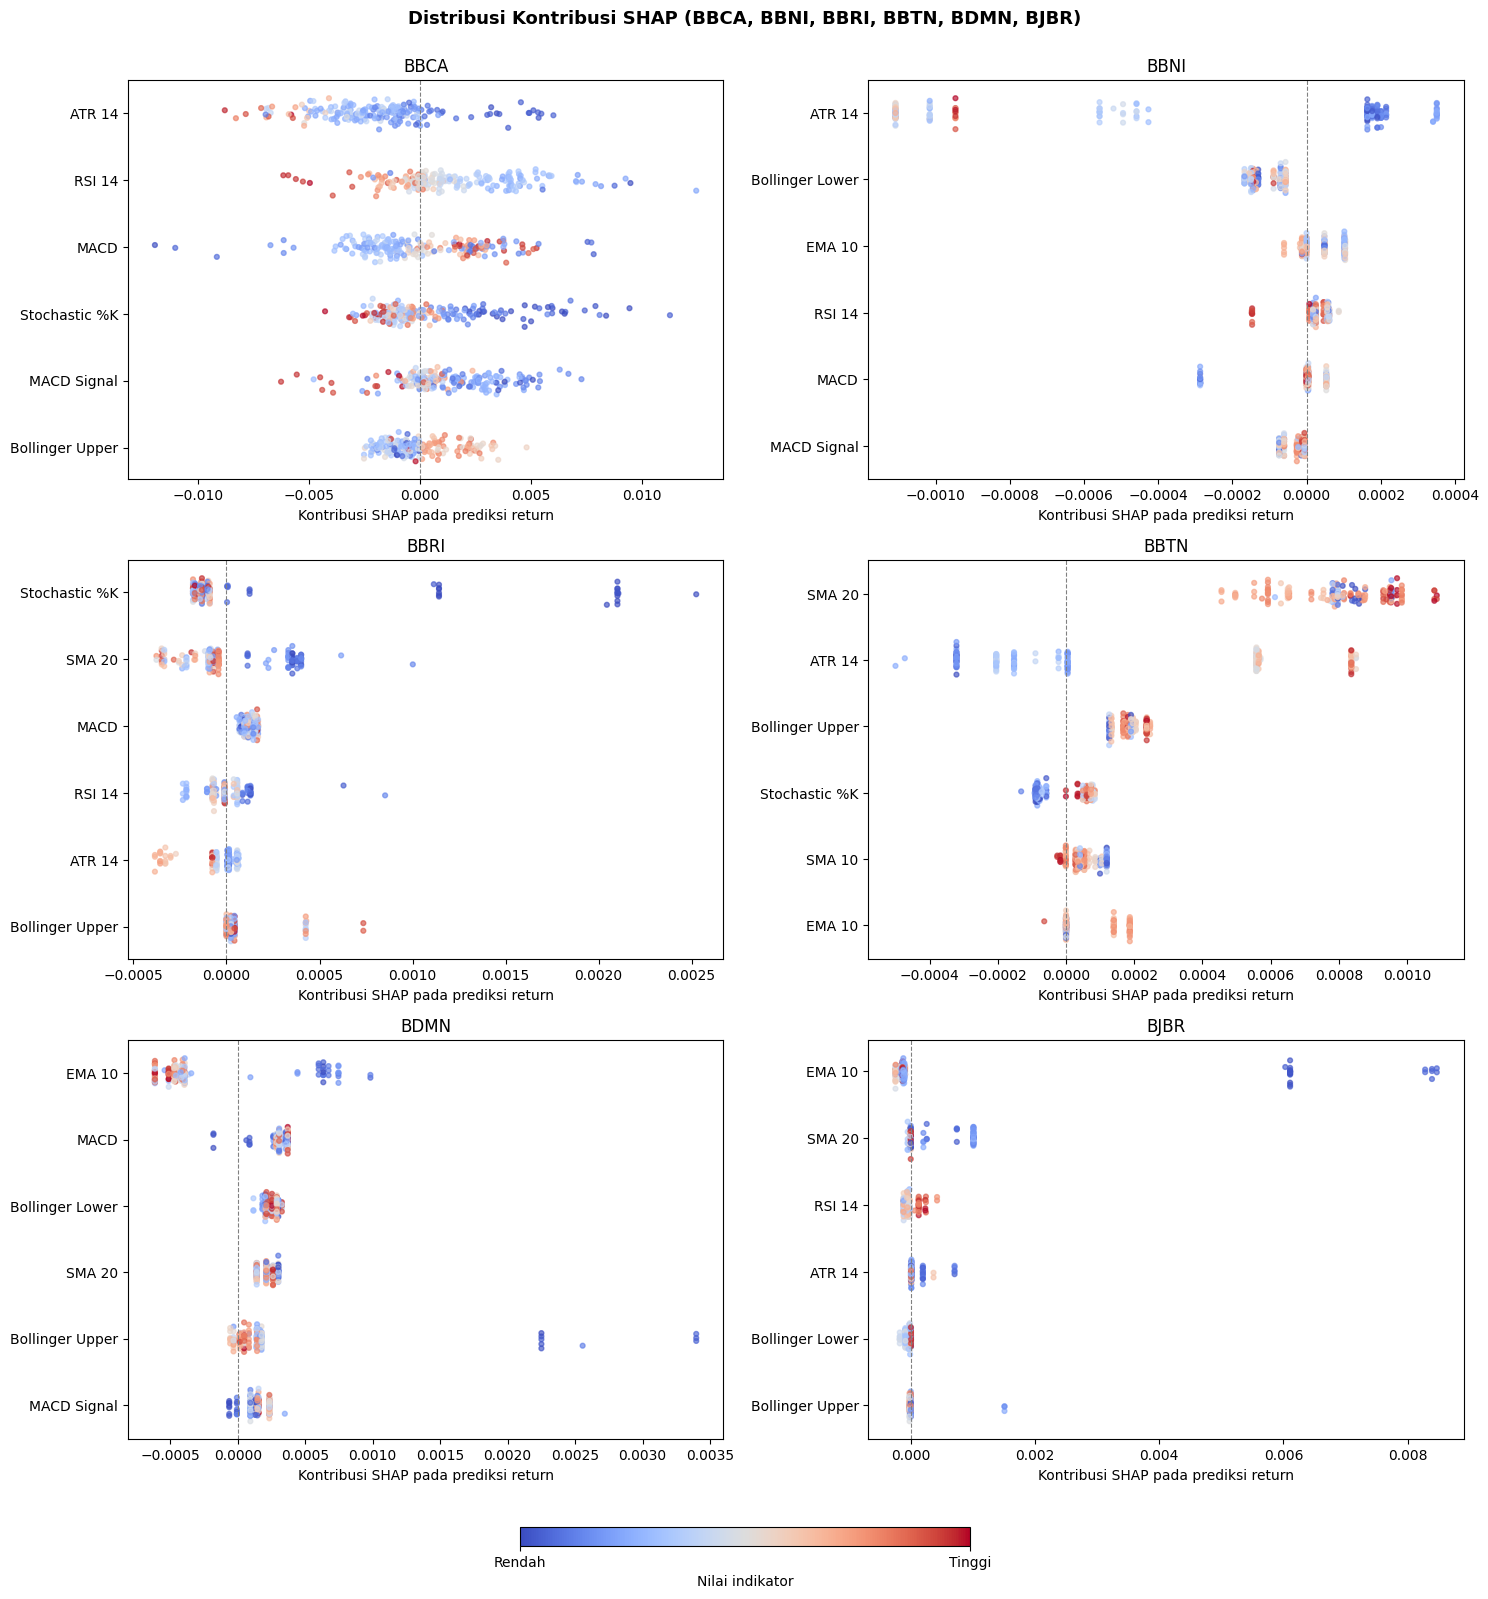

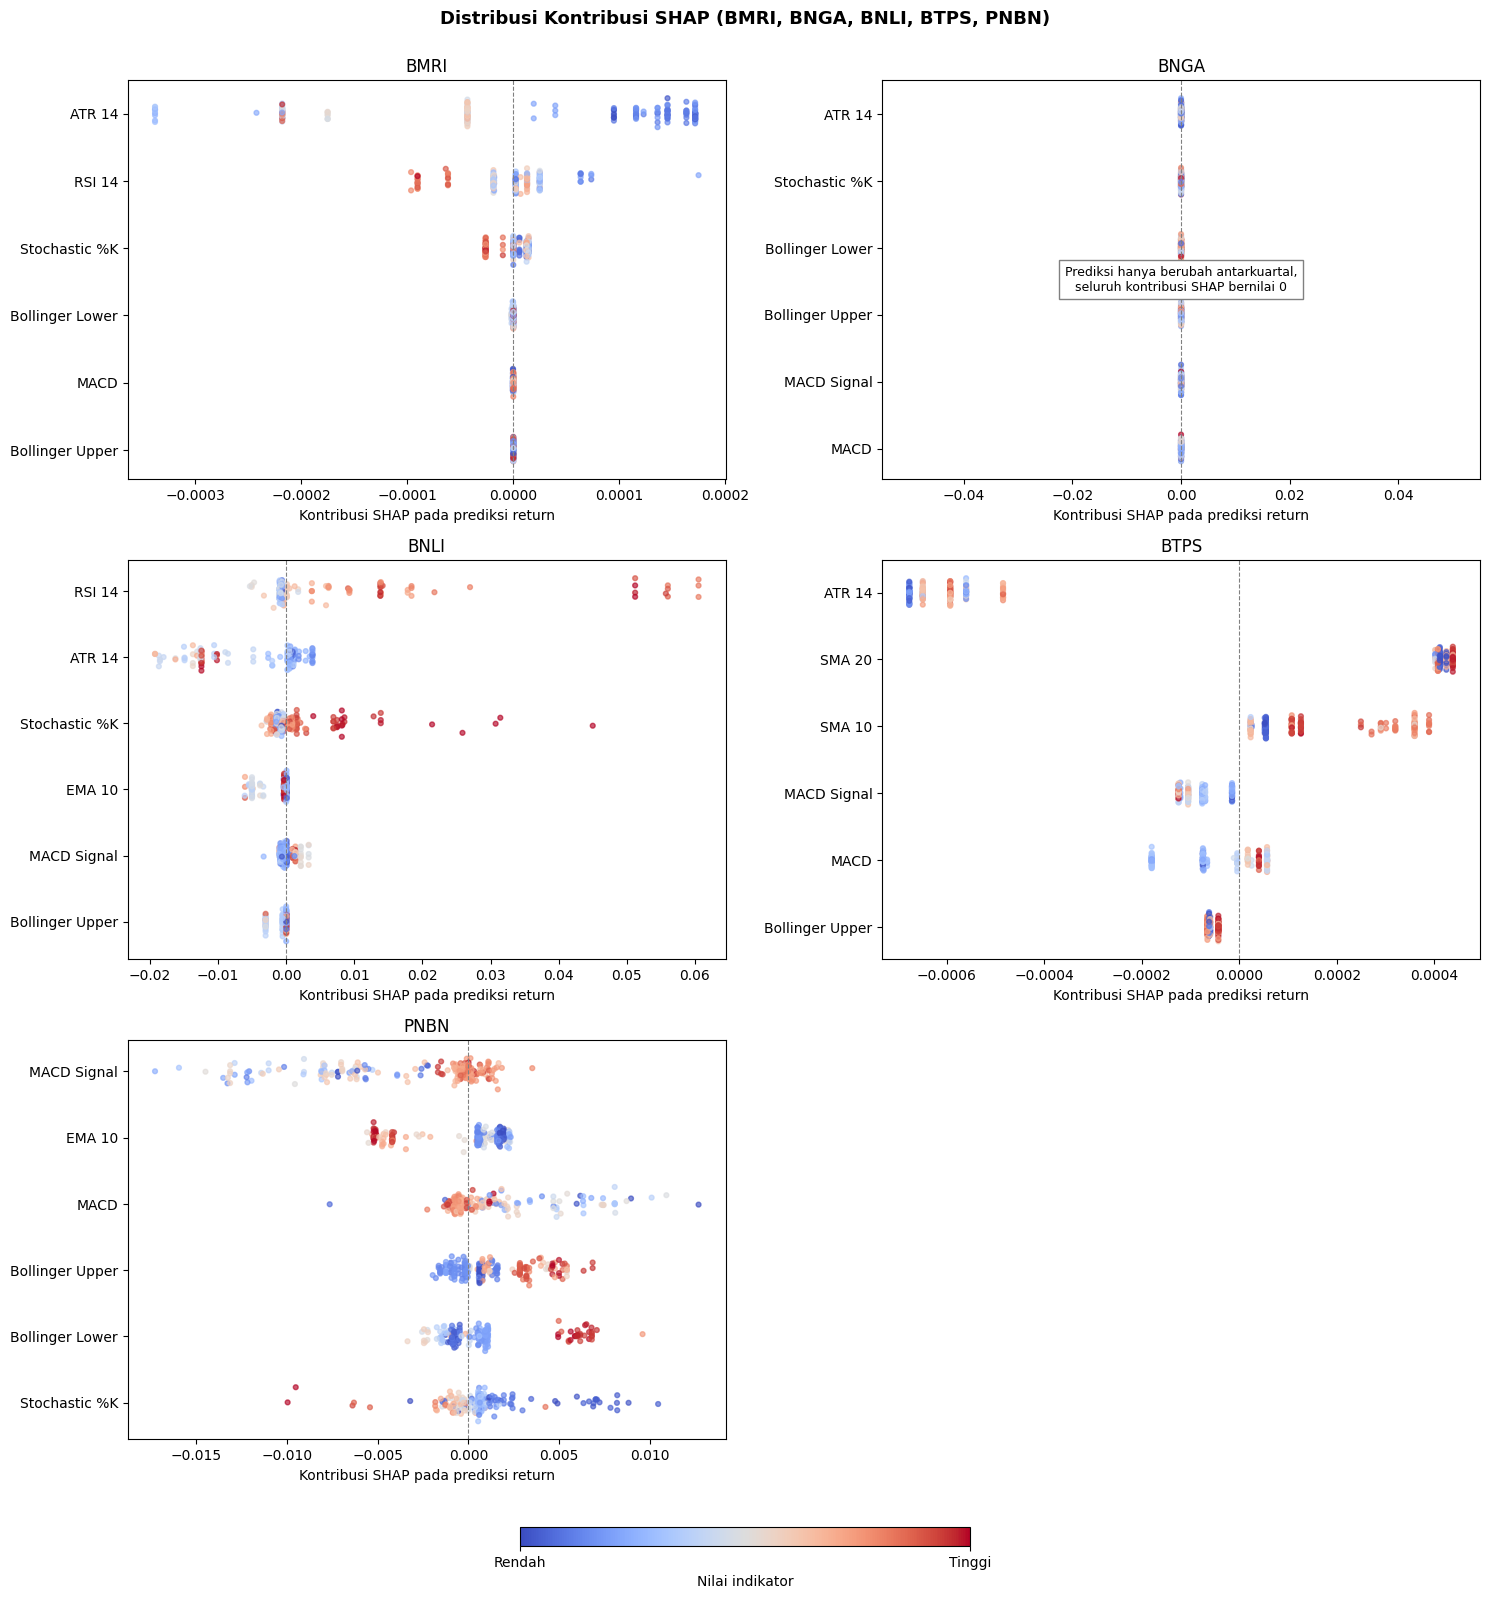

In [11]:
# grafik sebaran SHAP untuk sebelas saham, dibagi dua gambar
# warna titik itu nilai fitur, merah tinggi dan biru rendah
random_generator = np.random.default_rng(random_seed)
ticker_groups = [tickers[:6], tickers[6:]]
for part, group in enumerate(ticker_groups, start=1):
    fig, axes = plt.subplots(3, 2, figsize=(15, 16))
    # satu panel untuk tiap saham
    for axis, ticker in zip(axes.flat, group):
        ticker_shap = shap_rows[ticker]
        mean_abs = np.abs(ticker_shap).mean(axis=0)
        top_indices = np.argsort(mean_abs, kind="stable")[-plot_feature_count:]
        for position, feature_index in enumerate(top_indices):
            values = ticker_shap[:, feature_index]
            sample_size = min(plot_sample_size, len(values))
            # mengambil sampel untuk grafik tanpa mengubah hasil perhitungan SHAP
            sample = random_generator.choice(len(values), size=sample_size, replace=False)
            # menggeser posisi titik sedikit dengan jitter agar titik yang berdekatan terlihat
            jitter = random_generator.normal(0, 0.08, size=sample_size)
            color_values = feature_rows[ticker][sample, feature_index]
            axis.scatter(values[sample], position + jitter, c=color_values, cmap="coolwarm", s=12, alpha=0.65)
        axis.set_yticks(range(len(top_indices)), [display_names.get(features[index], features[index]) for index in top_indices])
        axis.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        axis.set_title(ticker)
        axis.set_xlabel("Kontribusi SHAP pada prediksi return")
        # saham yang seluruh kontribusinya nol diberi keterangan
        if np.allclose(ticker_shap, 0.0):
            axis.text(0.5, 0.5, "Prediksi hanya berubah antarkuartal,\nseluruh kontribusi SHAP bernilai 0",
                      transform=axis.transAxes, ha="center", va="center", fontsize=9,
                      bbox={"facecolor": "white", "edgecolor": "gray"})
    for unused_axis in axes.flat[len(group):]:
        unused_axis.set_visible(False)
    fig.suptitle(f"Distribusi Kontribusi SHAP ({', '.join(group)})", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0.05, 1, 0.98))
    # skala warna nilai indikator di bawah grafik
    color_axis = fig.add_axes((0.35, 0.02, 0.3, 0.012))
    color_bar = fig.colorbar(plt.cm.ScalarMappable(cmap="coolwarm"), cax=color_axis, orientation="horizontal", ticks=[0, 1])
    color_bar.ax.set_xticklabels(["Rendah", "Tinggi"])
    color_bar.set_label("Nilai indikator")
    fig.savefig(figure_dir / f"gambar_shap_bagian{part}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Perbandingan Peringkat Fitur

Peringkat fitur dari Gain Importance, Permutation Importance, dan SHAP ditampilkan dalam satu tabel dan heatmap. Perbandingan ini digunakan untuk melihat fitur yang menempati urutan serupa atau berbeda pada ketiga metode.

In [12]:
# membandingkan peringkat fitur dari ketiga metode
feature_ranking = pd.DataFrame(index=features)
feature_ranking["Rank Gain"] = gain_importance["Mean_Gain"].rank(ascending=False, method="min").astype(int)
feature_ranking["Rank Permutation"] = permutation_importance_df["Mean_Permutation"].rank(ascending=False, method="min").astype(int)
feature_ranking["Rank SHAP"] = shap_importance["Mean_SHAP"].rank(ascending=False, method="min").astype(int)
# rata-rata peringkat dari tiga metode, makin kecil makin penting
feature_ranking["Mean Rank"] = feature_ranking.mean(axis=1)
feature_ranking = feature_ranking.sort_values("Mean Rank").rename_axis("Indikator Teknikal").reset_index()
feature_ranking.to_parquet(output_dir / "feature_importance_summary.parquet", index=False)
show_table(feature_ranking.set_index("Indikator Teknikal"), display_names=display_names)


,Gain Rank,Permutation Rank,SHAP Rank,Mean Rank
Technical Indicator,,,,
RSI 14,1,2,1,1.33333
Stochastic %K,6,1,3,3.33333
ATR 14,2,9,2,4.33333
EMA 10,3,5,5,4.33333
MACD,4,4,6,4.66667
MACD Signal,10,3,4,5.66667
SMA 20,5,7,9,7
Bollinger Lower,7,8,8,7.66667
Bollinger Upper,8,10,7,8.33333


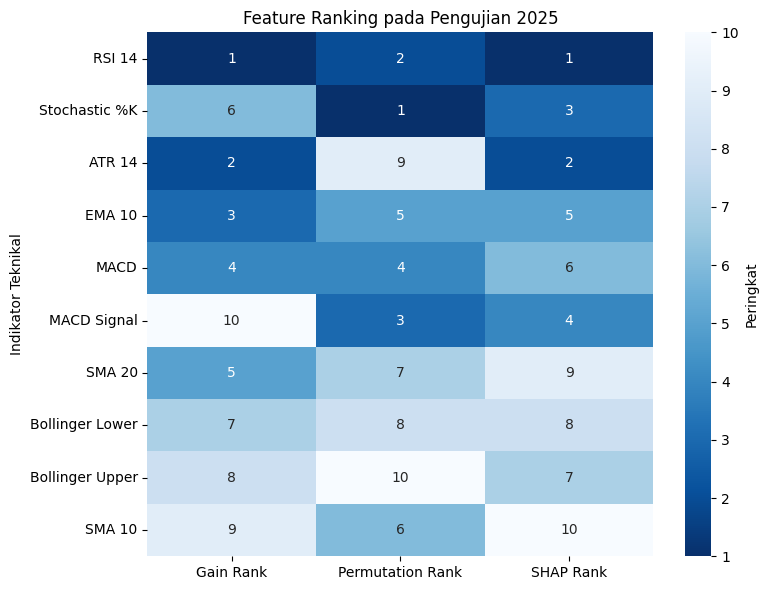

In [13]:
# menampilkan peringkat setiap metode dalam heatmap
fig, axis = plt.subplots(figsize=(8, 6))
heatmap_data = feature_ranking.set_index("Indikator Teknikal")[["Rank Gain", "Rank Permutation", "Rank SHAP"]]
sns.heatmap(heatmap_data.rename(index=display_names, columns=display_names), annot=True, fmt="d", cmap="Blues_r", ax=axis, cbar_kws={"label": "Peringkat"})
axis.set_title('Feature Ranking pada Pengujian 2025')
fig.tight_layout()
plt.show()
